In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [ ]:
file_path = '/content/sales_data_20 (1).xlsx'

In [ ]:
df = pd.read_excel(file_path)

In [ ]:
# 1. PANDAS OPERATIONS
print("=== PANDAS OPERATIONS ===")
print("First 5 Rows:\n", df.head())
print("\nDataset Shape:", df.shape)
print("\nDataset Info:")
df.info()

print("\nSummary Statistics:\n", df.describe())

high_sales_df = df[df['Sales ($)'] > 3000]

sorted_df = df.sort_values(by='Calculated Profit ($)', ascending=False)

df['Margin_Category'] = np.where(
    df['Profit Margin'] >= 0.05, 'High Margin', 'Low Margin'
)

summary_df = (
    df.groupby('Margin_Category')
    .agg(
        Total_Sales=('Sales ($)', 'sum'),
        Average_Profit=('Calculated Profit ($)', 'mean'),
        Category_Count=('ID', 'count'),
    )
    .reset_index()
)

print("\nMargin Classification Summary:\n", summary_df)

=== PANDAS OPERATIONS ===
First 5 Rows:
    ID Product Category  Sales ($)  Profit Margin  Calculated Profit ($)
0   1      Electronics       1000           0.05                   50.0
1   2  Office Supplies       5000           0.10                  500.0
2   3        Furniture       4000           0.04                  160.0
3   4     Raw Material       3000           0.03                   90.0
4   5         Hardware       2000           0.07                  140.0

Dataset Shape: (20, 5)

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 5 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   ID                     20 non-null     int64  
 1   Product Category       20 non-null     object 
 2   Sales ($)              20 non-null     int64  
 3   Profit Margin          20 non-null     float64
 4   Calculated Profit ($)  20 non-null     float64
dtypes: float64(2), in

In [ ]:
# numpy operation
print("\n=== NUMPY OPERATIONS ===")

sales_arr = df['Sales ($)'].to_numpy()
profit_arr = df['Calculated Profit ($)'].to_numpy()
categories_arr = df['Product Category'].to_numpy()

print(f"Mean Sales: ${np.mean(sales_arr):,.2f}")
print(f"Median Sales: ${np.median(sales_arr):,.2f}")
print(f"Standard Deviation of Sales: ${np.std(sales_arr):,.2f}")
print(f"90th Percentile Sales: ${np.percentile(sales_arr, 90):,.2f}")
print(f"Total Portfolio Profit: ${np.sum(profit_arr):,.2f}")

high_profit_mask = profit_arr > 200
high_profit_categories = categories_arr[high_profit_mask]
print("\nCategories with Profit > $200:\n", list(high_profit_categories))


=== NUMPY OPERATIONS ===
Mean Sales: $3,277.50
Median Sales: $2,300.00
Standard Deviation of Sales: $2,562.83
90th Percentile Sales: $7,100.00
Total Portfolio Profit: $3,755.50

Categories with Profit > $200:
 ['Office Supplies', 'Soaps', 'Hostels', 'Hotels', 'Restaurants']


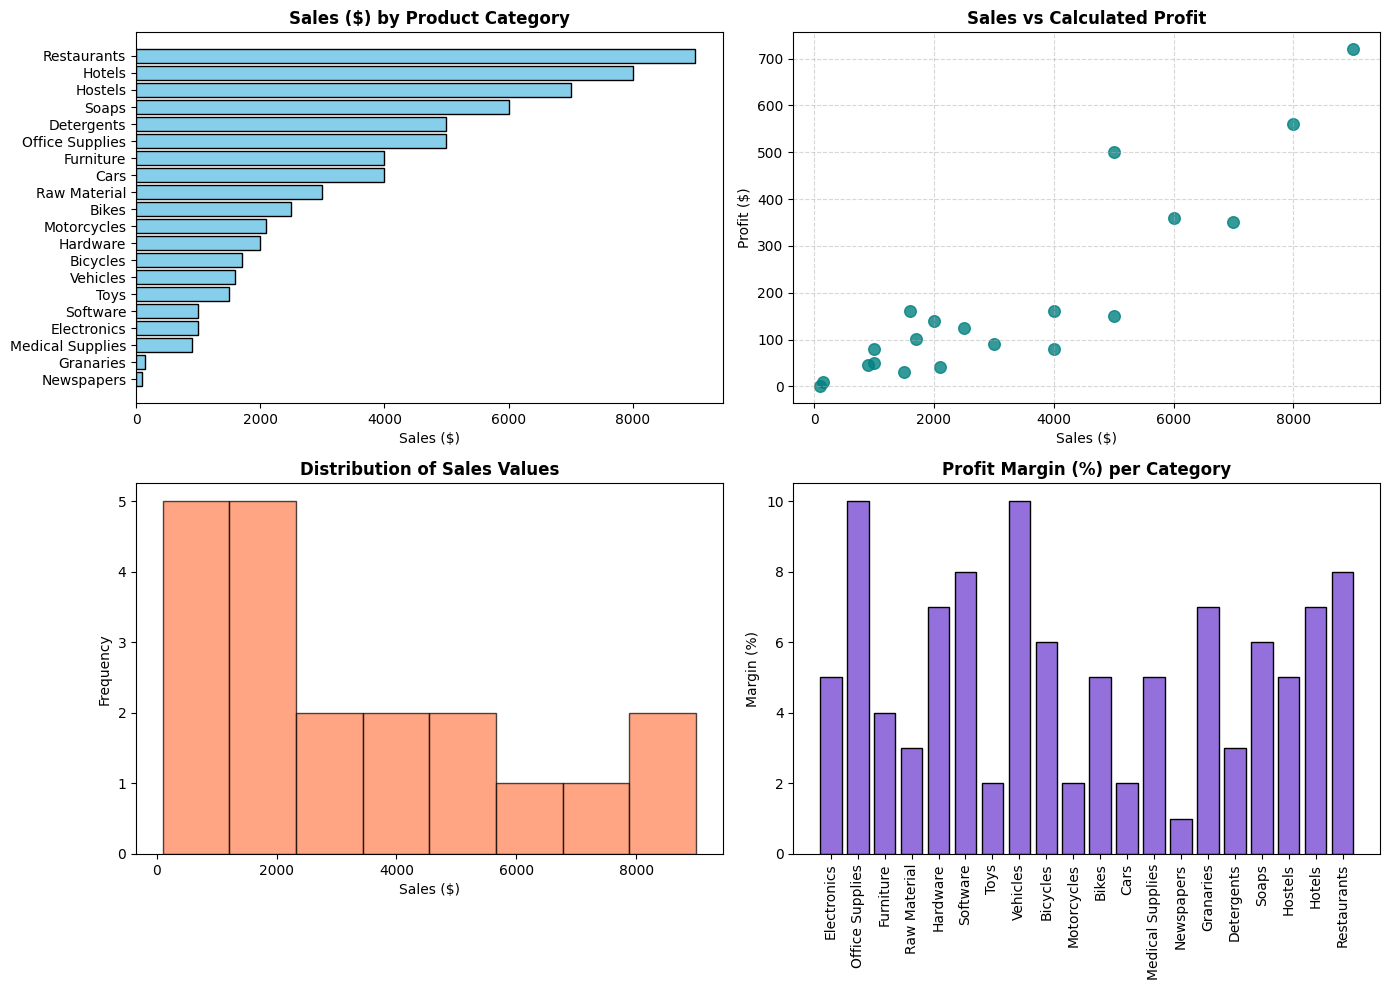

In [ ]:
# Matplotlib Visualization
plt.figure(figsize=(14, 10))

# Horizontal Bar Chart of Sales
plt.subplot(2, 2, 1)
df_sorted_sales = df.sort_values('Sales ($)')
plt.barh(
    df_sorted_sales['Product Category'],
    df_sorted_sales['Sales ($)'],
    color='skyblue',
    edgecolor='black',
)
plt.title('Sales ($) by Product Category', fontweight='bold')
plt.xlabel('Sales ($)')

# Scatter Plot of Sales vs Calculated Profit
plt.subplot(2, 2, 2)
plt.scatter(
    df['Sales ($)'],
    df['Calculated Profit ($)'],
    color='teal',
    s=70,
    alpha=0.8,
)
plt.title('Sales vs Calculated Profit', fontweight='bold')
plt.xlabel('Sales ($)')
plt.ylabel('Profit ($)')
plt.grid(True, linestyle='--', alpha=0.5)

#  Histogram of Sales Distribution
plt.subplot(2, 2, 3)
plt.hist(df['Sales ($)'], bins=8, color='coral', edgecolor='black', alpha=0.7)
plt.title('Distribution of Sales Values', fontweight='bold')
plt.xlabel('Sales ($)')
plt.ylabel('Frequency')

# Profit Margin (%) Bar Chart
plt.subplot(2, 2, 4)
plt.bar(
    df['Product Category'],
    df['Profit Margin'] * 100,
    color='mediumpurple',
    edgecolor='black',
)
plt.title('Profit Margin (%) per Category', fontweight='bold')
plt.ylabel('Margin (%)')
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()